# KL divergence and parameter dependence with PCAT

How much does an observation change a distribution, and how strongly do its posterior parameters depend on one another? Those are different questions.

We use a two-dimensional Gaussian prior with mean $(-0.3, 0.4)$ and standard deviations $(1.1, 0.8)$. A synthetic observation $(0.9, -0.8)$ has Gaussian likelihood covariance $[[0.35, 0.12], [0.12, 0.5]]$. The example samples that posterior with PCAT and evaluates normalized analytic densities on the actual retained draws.

The forward KL divergence $D_{\mathrm{KL}}(P_{\mathrm{post}}\Vert P_{\mathrm{prior}})$ describes the change relative to the specified prior. Mutual information $I(X;Y)=D_{\mathrm{KL}}(p(X,Y)\Vert p(X)p(Y))$ describes dependence between the two posterior parameters. Both are reported in nats and compared with their analytic Gaussian values. Marginal densities are supplied explicitly rather than fitted to the chain.

The call requests 3000 post-burn draws per chain after 1000 burn-in sweeps. Convergence-based stopping can retain fewer draws, so the posterior summary below uses the arrays actually returned. Monte Carlo error estimates account for chain autocorrelation and variation between independent chains. Agreement with an analytic value alone does not establish convergence, and finite-sample information estimates can be negative.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

working_directory = Path.cwd()
candidates = [working_directory] + [
    parent / "examples" / "kl_divergence_gaussian"
    for parent in (working_directory, *working_directory.parents)
]
example_directory = next(path for path in candidates if (path / "kl_divergence_gaussian.py").is_file())
if str(example_directory) not in sys.path:
    sys.path.insert(0, str(example_directory))

from kl_divergence_gaussian import PARAMETER_NAMES, run_example

result = run_example()
information = result["mutual_information"]
comparison = pd.DataFrame({
    "Measure": ["Posterior-to-prior KL", "Posterior parameter MI"],
    "Estimate [nats]": [result["kl_divergence"], information["mutual_information"]],
    "MCSE [nats]": [result["standard_error"], information["standard_error"]],
    "Analytic [nats]": [result["analytic_kl"], result["analytic_mutual_information"]],
    "Effective draws": [result["effective_sample_size"], information["effective_sample_size"]],
})
display(comparison.round({"Estimate [nats]": 3, "MCSE [nats]": 3, "Analytic [nats]": 3, "Effective draws": 0}))
posterior = pd.DataFrame(result["chains"].reshape(-1, len(PARAMETER_NAMES)), columns=PARAMETER_NAMES)
display(posterior.describe().round(3))

,Measure,Estimate [nats],MCSE [nats],Analytic [nats],Effective draws
0,Posterior-to-prior KL,1.349,0.045,1.387,484.0
1,Posterior parameter MI,0.016,0.005,0.019,1391.0


,x,y
count,5000.000,5000.000
mean,0.720,-0.345
std,0.533,0.530
min,-1.001,-2.366
25%,0.339,-0.703
50%,0.724,-0.331
75%,1.075,0.013
max,2.262,1.436


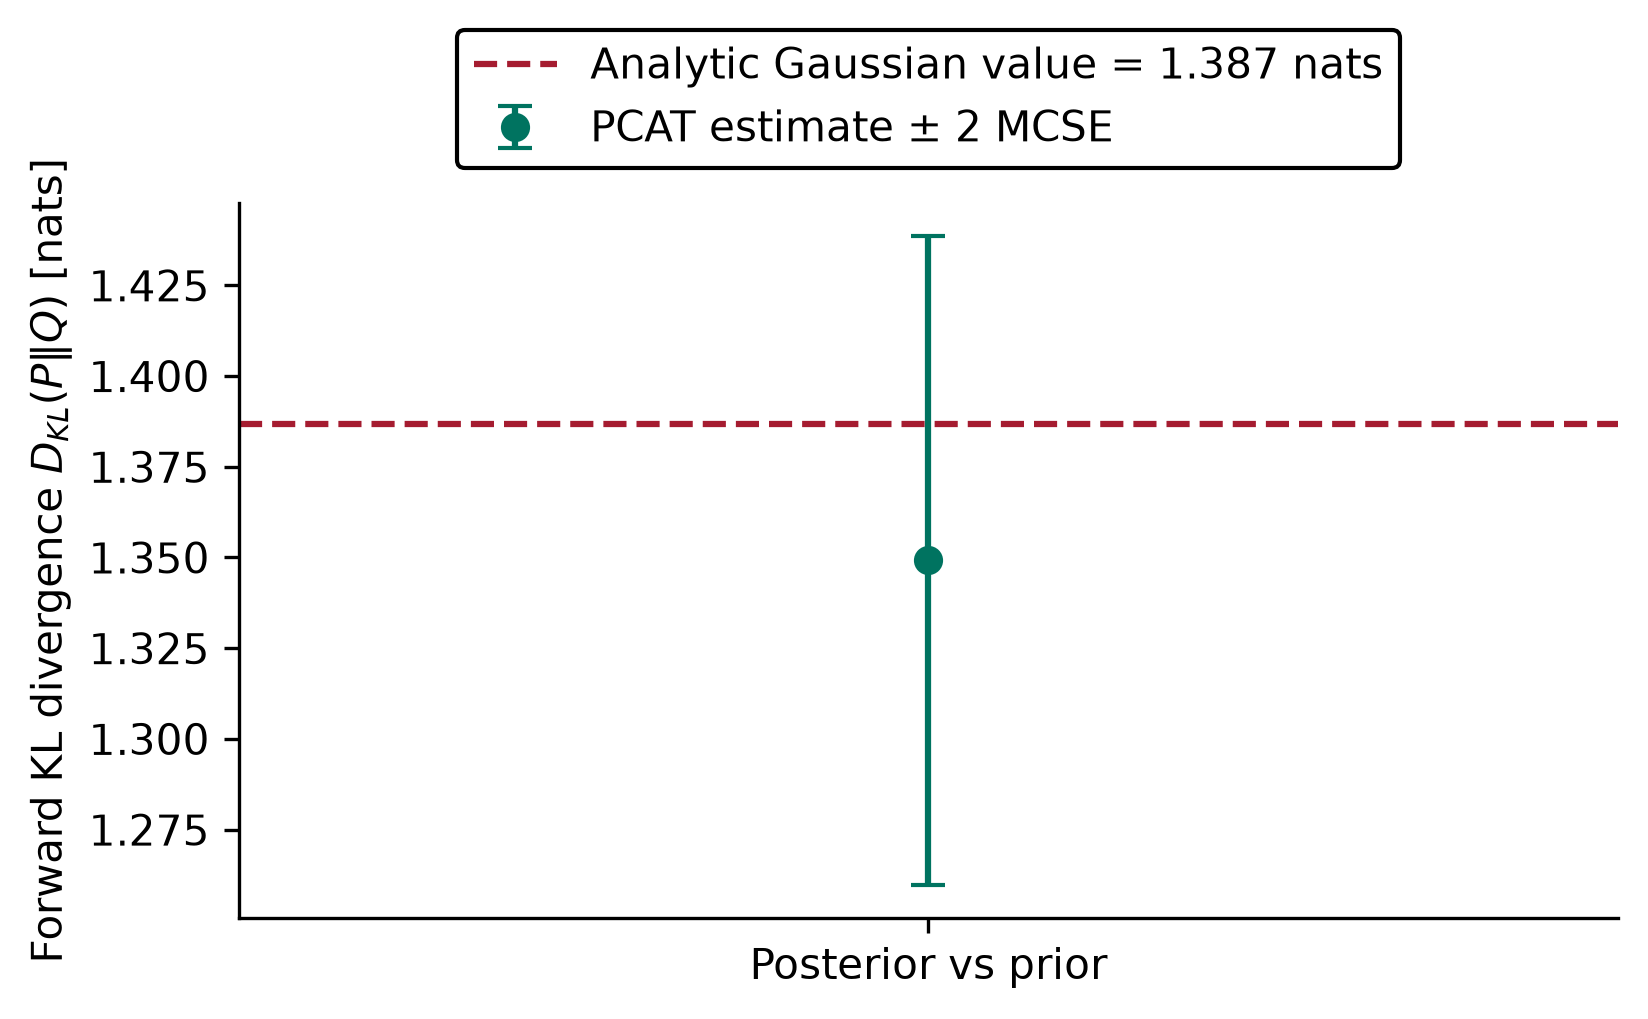

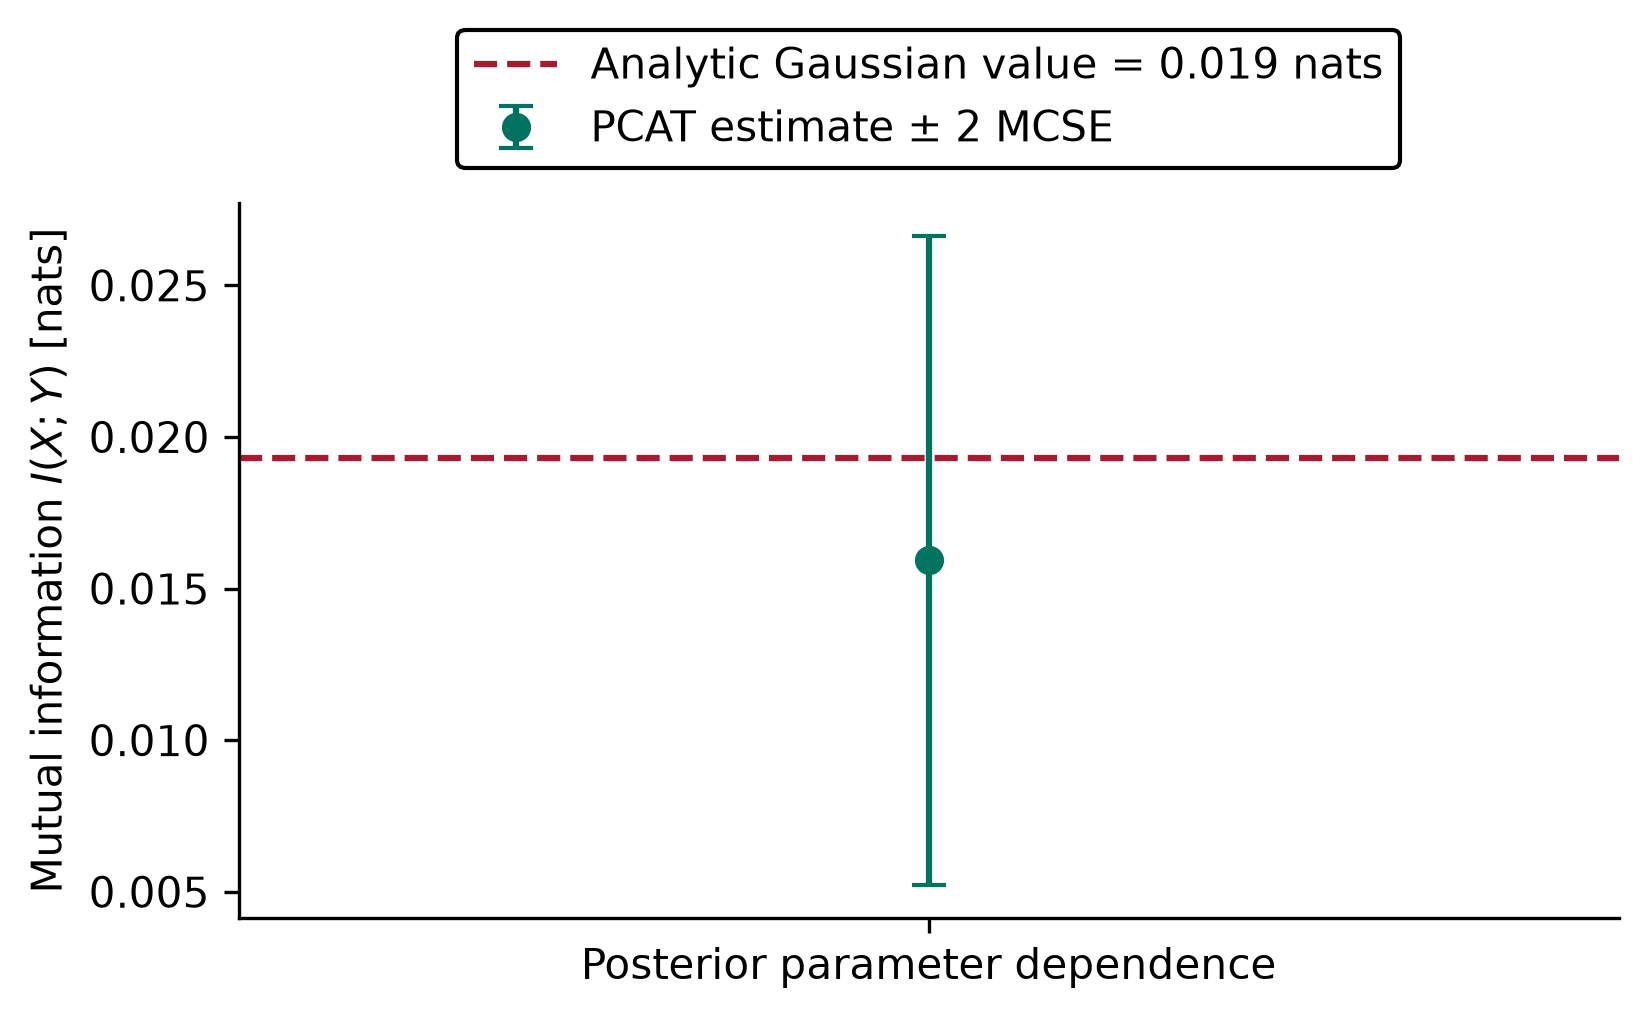

In [2]:
display(Image(
    filename=str(result["figure_path"]),
    alt="PCAT posterior-to-prior KL estimate with twice its Monte Carlo standard error, compared with the analytic Gaussian divergence.",
))
display(Image(
    filename=str(result["mutual_information_figure_path"]),
    alt="Mutual information between PCAT posterior parameters with twice its Monte Carlo standard error, compared with the analytic correlated-Gaussian value.",
))